# D3 Penalty Summary

Compute the barrier MAE and empirical coverage MAE summary for the `d3_sweep_single_curve` results.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd


RESULTS_DIR = Path("/mnt/home/philipaa/scratch/barrier-paper-results/d3_sweep_single_curve")
PENALTY_ORDER = ["1", "1e1", "1e2"]
COVERAGE_LEVELS = [0, 25, 50, 68, 90, 95, 100]
FILENAME_RE = re.compile(
    r"(?P<dataset>.+)_curve0_bnn_soc_d3lam_(?P<penalty>1e2|1e1|1)\.h5\.csv$"
)

In [2]:
rows = []

for csv_path in sorted(RESULTS_DIR.glob("*.h5.csv")):
    match = FILENAME_RE.match(csv_path.name)
    if match is None:
        continue

    df = pd.read_csv(csv_path)
    df["barrier_MAE"] = pd.to_numeric(df["barrier_MAE"], errors="coerce")

    empirical_coverage = np.array(
        [pd.to_numeric(df[f"barrier_emp_cov_{level}"], errors="coerce").mean() * 100 for level in COVERAGE_LEVELS],
        dtype=float,
    )
    coverage_abs_error = np.abs(empirical_coverage - np.array(COVERAGE_LEVELS, dtype=float))

    rows.append(
        {
            "dataset": match.group("dataset"),
            "penalty": match.group("penalty"),
            "barrier_MAE": df["barrier_MAE"].mean(),
            "EC_MAE_pct": np.nanmean(coverage_abs_error),
        }
    )

metrics = pd.DataFrame(rows)

summary = (
    metrics.groupby("penalty")[["barrier_MAE", "EC_MAE_pct"]]
    .agg(["mean", "median", "std"])
    .loc[PENALTY_ORDER]
)

for metric in ["barrier_MAE", "EC_MAE_pct"]:
    metrics[f"{metric}_rank"] = metrics.groupby("dataset")[metric].rank(method="min", ascending=True)

wins = pd.DataFrame(
    {
        metric: (
            metrics.loc[metrics.groupby("dataset")[metric].idxmin(), "penalty"]
            .value_counts()
            .reindex(PENALTY_ORDER, fill_value=0)
        )
        for metric in ["barrier_MAE", "EC_MAE_pct"]
    }
)

print(f"Loaded {len(metrics)} CSV files across {metrics['dataset'].nunique()} datasets.")
print("\nSummary by D3 penalty:")
print(summary.to_string(float_format=lambda value: f"{value:.3f}"))
print("\nWins by metric, out of 16 datasets:")
print(wins.to_string())

Loaded 48 CSV files across 16 datasets.

Summary by D3 penalty:
        barrier_MAE                EC_MAE_pct             
               mean  median    std       mean median   std
penalty                                                   
1           123.362 117.596 69.335      6.344  5.924 3.235
1e1         101.462  81.319 71.555      5.606  4.286 3.388
1e2         115.475  85.659 72.707      7.535  5.622 5.406

Wins by metric, out of 16 datasets:
         barrier_MAE  EC_MAE_pct
penalty                         
1                  7           5
1e1                7           6
1e2                2           5


/opt/software-current/2023.06/x86_64/intel/skylake_avx512/software/Python-bundle-PyPI/2023.06-GCCcore-12.3.0/lib/python3.11/site-packages/pyparsing/core.py:5596: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString


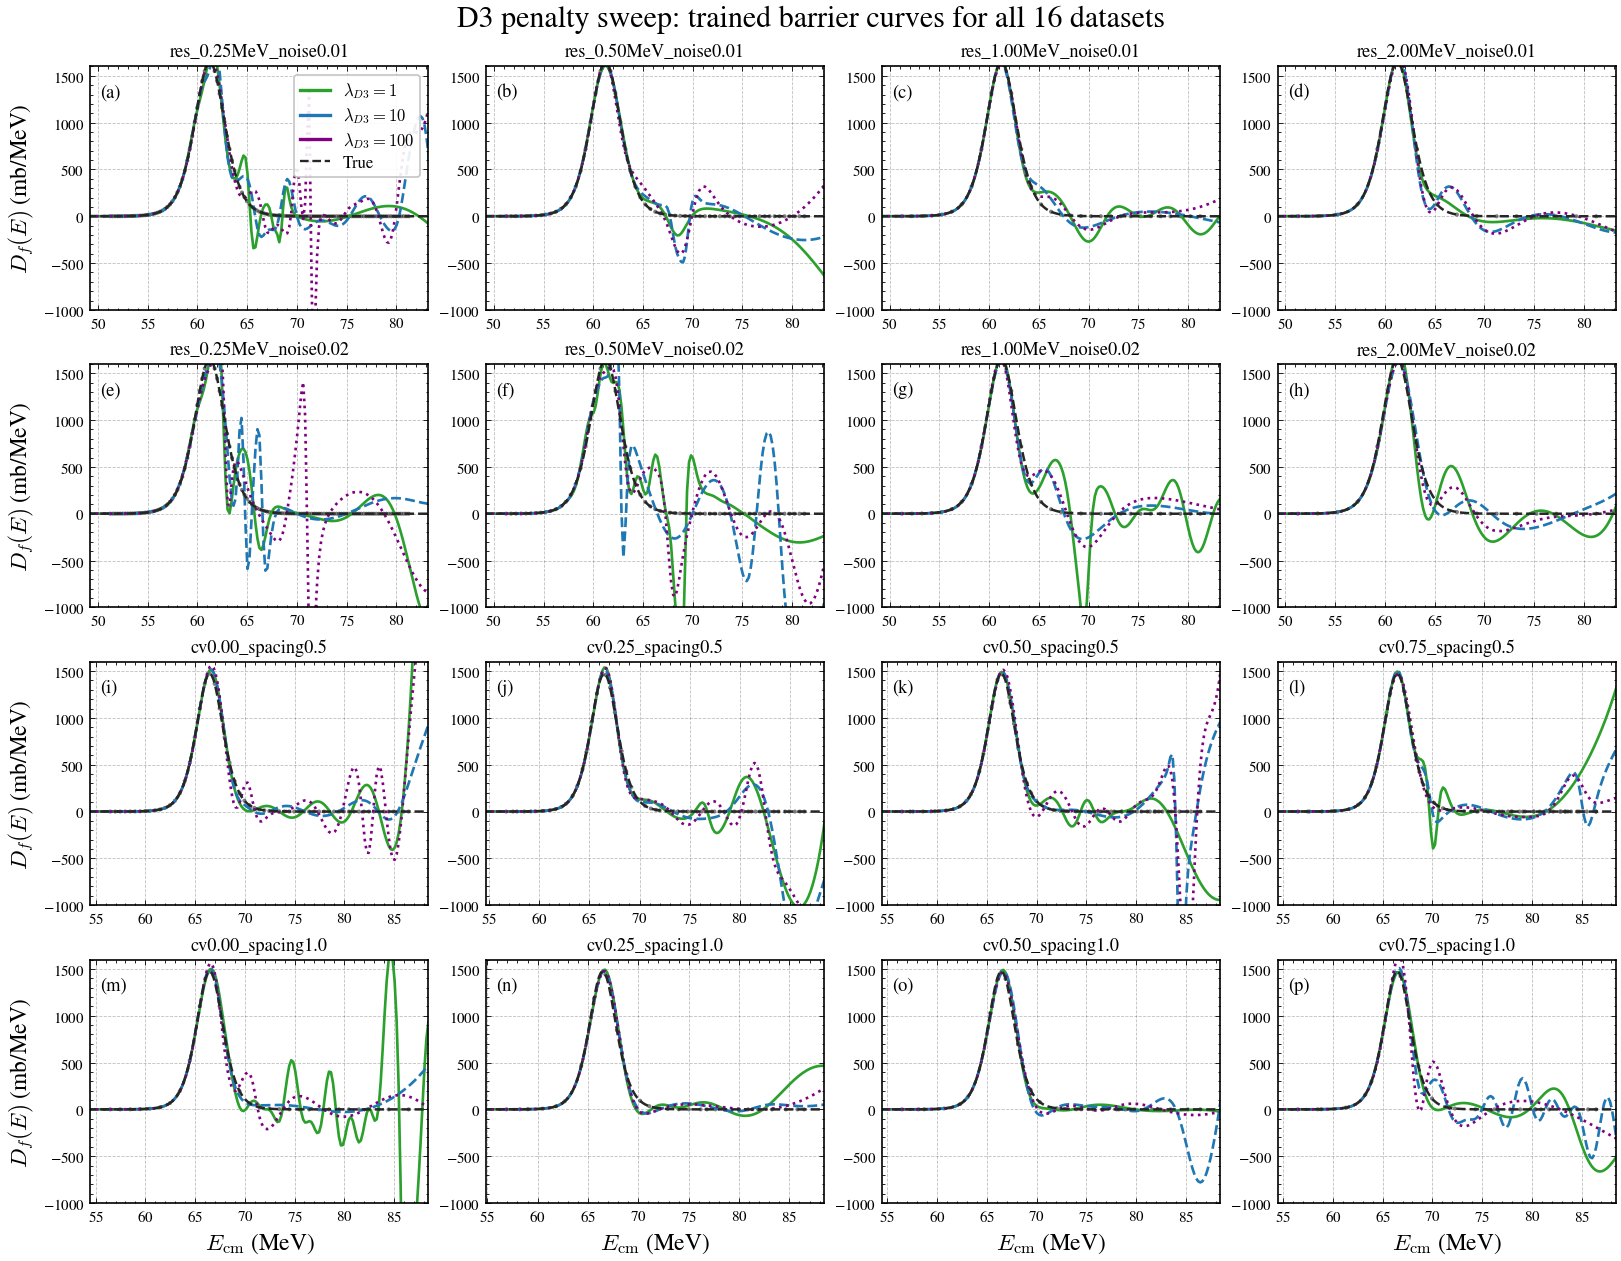

../plots/d3_penalty_16_dataset_barrier_curve_grid.png
../plots/d3_penalty_16_dataset_barrier_curve_grid.pdf


In [3]:
# Plot the trained barrier curves for each D3 penalty across all 16 datasets.
import h5py
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

try:
    import scienceplots
    plt.style.use(['science', 'no-latex', 'ieee', 'grid'])
except ModuleNotFoundError:
    pass

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 14,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 10,
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.0,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
})

PENALTY_LABELS = {
    "1": r"$\lambda_{D3}=1$",
    "1e1": r"$\lambda_{D3}=10$",
    "1e2": r"$\lambda_{D3}=100$",
}
PENALTY_COLORS = {
    "1": "tab:green",
    "1e1": "tab:blue",
    "1e2": "purple",
}


def dataset_sort_key(dataset):
    res_match = re.match(r"res_(?P<res>[0-9.]+)MeV_noise(?P<noise>[0-9.]+)", dataset)
    if res_match:
        return (0, float(res_match.group("noise")), float(res_match.group("res")), dataset)
    cv_match = re.match(r"cv(?P<cv>[0-9.]+)_spacing(?P<spacing>[0-9.]+)", dataset)
    if cv_match:
        return (1, float(cv_match.group("spacing")), float(cv_match.group("cv")), dataset)
    return (2, dataset)


def d3_h5_path(dataset, penalty):
    return RESULTS_DIR / f"{dataset}_curve0_bnn_soc_d3lam_{penalty}.h5"


def first_group(h5_file):
    return h5_file[sorted(h5_file.keys())[0]]


def wong_sigma(E, E0, R0, hbarw):
    return 10.0 * (0.5 * R0**2 * hbarw / E) * np.log(
        1.0 + np.exp(2.0 * np.pi * (E - E0) / hbarw)
    )


def barrier_from_sigma(E, sigma):
    return np.gradient(np.gradient(E * sigma, E, edge_order=2), E, edge_order=2)


def load_d3_curve(dataset, penalty):
    with h5py.File(d3_h5_path(dataset, penalty), "r") as f:
        grp = first_group(f)
        x_pred = grp["x_pred"][()]
        d2_samples = grp["d2_samples"][()]
        E_data = grp["E_data"][()]
        attrs = dict(grp.attrs)

    E0 = float(attrs["E0_true"])
    R0 = float(attrs["R0_true"])
    hw = float(attrs["hw_true"])
    true_barrier = barrier_from_sigma(x_pred, wong_sigma(x_pred, E0, R0, hw))

    return {
        "x_pred": x_pred,
        "d_mean": np.nanmean(d2_samples, axis=0),
        "d_low": np.nanpercentile(d2_samples, 2.5, axis=0),
        "d_high": np.nanpercentile(d2_samples, 97.5, axis=0),
        "E_data": E_data,
        "true_barrier": true_barrier,
    }


datasets = sorted(metrics["dataset"].unique(), key=dataset_sort_key)
if len(datasets) != 16:
    raise ValueError(f"Expected 16 datasets, found {len(datasets)}")

fig, axes = plt.subplots(4, 4, figsize=(13.5, 10.5), sharex=False, sharey=False, constrained_layout=True)
axes = axes.ravel()

for idx, (dataset, ax) in enumerate(zip(datasets, axes)):
    ref = None
    for penalty in PENALTY_ORDER:
        curve = load_d3_curve(dataset, penalty)
        ref = curve
        ax.plot(
            curve["x_pred"],
            curve["d_mean"],
            color=PENALTY_COLORS[penalty],
            lw=1.6,
            label=PENALTY_LABELS[penalty],
        )

    ax.plot(ref["x_pred"], ref["true_barrier"], color="0.15", lw=1.5, ls="--", label="True")
    ax.scatter(
        ref["E_data"],
        np.interp(ref["E_data"], ref["x_pred"], ref["true_barrier"]),
        s=6,
        color="0.15",
        alpha=0.6,
        edgecolor="none",
    )
    ax.set_title(dataset)
    ax.set_xlim(ref["E_data"].min() - 2.0, ref["E_data"].max() + 2.0)
    ax.set_ylim(-1000, 1600)
    ax.tick_params(direction="in")
    ax.text(
        0.03,
        0.93,
        f"({chr(97 + idx)})",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=11,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.0),
    )

for ax in axes[12:]:
    ax.set_xlabel(r"$E_{\mathrm{cm}}$ (MeV)")
for ax in axes[::4]:
    ax.set_ylabel(r"$D_f(E)$ (mb/MeV)")

handles = [
    Line2D([0], [0], color=PENALTY_COLORS[penalty], lw=2.0, label=PENALTY_LABELS[penalty])
    for penalty in PENALTY_ORDER
]
handles.append(Line2D([0], [0], color="0.15", lw=1.4, ls="--", label="True"))
axes[0].legend(
    handles=handles,
    loc="upper right",
    frameon=True,
    framealpha=0.9,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.35,
    labelspacing=0.3,
    handlelength=1.8,
)

fig.suptitle("D3 penalty sweep: trained barrier curves for all 16 datasets", fontsize=18)
out_dir = Path("../plots")
out_dir.mkdir(parents=True, exist_ok=True)
curve_grid_png = out_dir / "d3_penalty_16_dataset_barrier_curve_grid.png"
curve_grid_pdf = out_dir / "d3_penalty_16_dataset_barrier_curve_grid.pdf"
fig.savefig(curve_grid_png, dpi=300, bbox_inches="tight")
fig.savefig(curve_grid_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

print(curve_grid_png)
print(curve_grid_pdf)
